# 03. Regularization Techniques (Ridge & Lasso Regression)
### Integrated Project: AI-Based Intelligent Trading System — Assignment 3

---

## 1. Title and Objective

### Understanding Regularization in Supervised Learning
In Ordinary Least Squares (OLS) regression (Assignment 2), the objective is to minimize the unconstrained Residual Sum of Squares (RSS):
$$\min_{\boldsymbol{\beta}} \text{RSS}(\boldsymbol{\beta}) = \sum_{i=1}^{n} \left( y_i - \beta_0 - \sum_{j=1}^{p} \beta_j X_{ij} \right)^2$$

When explanatory features are numerous or highly correlated (multicollinear), OLS coefficient estimates suffer from **variance inflation**: tiny perturbations in training data produce large, unstable swings in weights. **Regularization** remedies this by adding a penalty term ($P(\boldsymbol{\beta})$) scaled by a tuning hyperparameter ($\alpha \ge 0$):
$$\min_{\boldsymbol{\beta}} \left[ \text{RSS}(\boldsymbol{\beta}) + \alpha \cdot P(\boldsymbol{\beta}) \right]$$

### The Two Core Regularization Families:
1. **Ridge Regression ($L_2$ Regularization / Tikhonov)**:
   $$P(\boldsymbol{\beta}) = \sum_{j=1}^{p} \beta_j^2 = \|\boldsymbol{\beta}\|_2^2$$
   - Penalizes the sum of squared coefficients.
   - Shrinks collinear weights smoothly toward zero without setting them exactly to zero.
   - Resolves the near-singular matrix inversion $(\mathbf{X}^T \mathbf{X} + \alpha \mathbf{I})^{-1}\mathbf{X}^T \mathbf{y}$, dampening variance under extreme multicollinearity.
2. **Lasso Regression ($L_1$ Regularization / Least Absolute Shrinkage and Selection Operator)**:
   $$P(\boldsymbol{\beta}) = \sum_{j=1}^{p} |\beta_j| = \|\boldsymbol{\beta}\|_1$$
   - Penalizes the sum of absolute coefficient values.
   - Due to the sharp corner geometry of the $L_1$ ball, Lasso drives redundant coefficients **exactly to zero**, performing automatic **feature selection** and producing sparse, interpretable models.

### Multi-Company Asset Scope
We evaluate Ridge and Lasso across our **10-company multi-asset equity universe**:
- `AAPL`, `MSFT`, `GOOGL`, `AMZN`, `NVDA`, `META`, `TSLA`, `JPM`, `V`, `JNJ`
- Each company is modeled independently using **11 models** (1 OLS baseline + 5 Ridge alphas + 5 Lasso alphas) for a total of **110 model evaluations**.

### Assignment 3 Workflow:
1. Objective & Mathematical Foundations
2. Imports
3. Dataset Loading & Target Creation (Next-Day Close)
4. Multi-Company Setup & Train/Test Split (80/20 chronological per company)
5. Feature Scaling (StandardScaler fitted strictly on training data)
6. OLS Baseline Models (10 models)
7. Ridge Regression across Alphas: [0.01, 0.1, 1.0, 10.0, 100.0]
8. Lasso Regression across Alphas: [0.0001, 0.001, 0.01, 0.1, 1.0]
9. Model Comparison (Test RMSE and R² across models and companies)
10. Coefficient Analysis & Shrinkage Trajectories
11. Lasso Feature Selection & Sparsity Audit
12. Optional TimeSeriesSplit Cross-Validation Demonstration
13. Critical Financial Interpretation & Limitations
14. Final Dataset Export & Quality Checks
15. Conclusion


---

## 2. Import Libraries
We import scientific packages, linear models (`LinearRegression`, `Ridge`, `Lasso`), preprocessing scalers, cross-validation tools, and evaluation metrics.


In [1]:
import os
import sys
from pathlib import Path

# Ensure project root is in the Python path
PROJECT_ROOT = Path("..").resolve() if Path("..").resolve().name == "AI-Intelligent-Trading-System" else Path(".").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler

# Configure visualization styling
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["figure.dpi"] = 120
plt.rcParams["font.size"] = 10
sns.set_palette("muted")

print(f"Project Root: {PROJECT_ROOT}")
print("Libraries imported successfully!")


Project Root: C:\Users\pushk\OneDrive\Desktop\Pushkar\AI-Intelligent-Trading-System
Libraries imported successfully!


---

## 3. Dataset Loading & Target Creation
We load `data/processed/multi_company_features.csv` (15,010 clean rows across 10 companies) and compute the forward-looking target within each ticker:
$$\text{Target\_Next\_Close}_t = Close_{t+1} = \text{Close.shift(-1)}$$

We remove the final observation of each company (`2024-12-31`), which lacks a future close in the dataset. This yields **15,000 usable observations** (exactly 1,500 per company).


In [2]:
features_path = PROJECT_ROOT / "data" / "processed" / "multi_company_features.csv"
df_features = pd.read_csv(features_path)
df_features["Date"] = pd.to_datetime(df_features["Date"])
df_features = df_features.sort_values(by=["Ticker", "Date"]).reset_index(drop=True)

EXPECTED_TICKERS = sorted(["AAPL", "MSFT", "GOOGL", "AMZN", "NVDA", "META", "TSLA", "JPM", "V", "JNJ"])
COMPANY_NAMES = {
    "AAPL": "Apple", "MSFT": "Microsoft", "GOOGL": "Alphabet", "AMZN": "Amazon",
    "NVDA": "NVIDIA", "META": "Meta Platforms", "TSLA": "Tesla", "JPM": "JPMorgan Chase",
    "V": "Visa", "JNJ": "Johnson & Johnson"
}

# 1. Create target independently per company
df_features["Target_Next_Close"] = df_features.groupby("Ticker")["Close"].shift(-1)

# 2. Drop the final row of each company
df_reg = df_features.dropna(subset=["Target_Next_Close"]).reset_index(drop=True)

print(f"Total Usable Observations: {len(df_reg):,} (expected 15,000)")
print(f"Usable Rows per Ticker:    {len(df_reg) // len(EXPECTED_TICKERS):,} for all 10 companies")
assert len(df_reg) == 15000, f"Expected 15000, got {len(df_reg)}"
assert all(len(df_reg[df_reg['Ticker'] == t]) == 1500 for t in EXPECTED_TICKERS)


Total Usable Observations: 15,000 (expected 15,000)
Usable Rows per Ticker:    1,500 for all 10 companies


---

## 4. Multi-Company Setup & Chronological Train/Test Split
We use the same 13 explanatory features as Assignment 2:
- `Open, High, Low, Close, Volume`
- `Daily_Return, Price_Range, Candle_Body, Upper_Shadow, Lower_Shadow`
- `SMA_5, SMA_10, Volatility_5`

### Strict Chronological Partitioning (No Random Shuffling)
For each company independently:
- **Training Set (First 80%)**: 1,200 observations (`2019-01-15` to `2023-10-19`)
- **Testing Set (Last 20%)**: 300 observations (`2023-10-20` to `2024-12-30`)
- **Total**: 12,000 train observations, 3,000 test observations.


In [3]:
feature_cols = [
    "Open", "High", "Low", "Close", "Volume",
    "Daily_Return", "Price_Range", "Candle_Body",
    "Upper_Shadow", "Lower_Shadow", "SMA_5", "SMA_10", "Volatility_5"
]

# Pre-split each company into Train and Test subsets with strict scaling
data_partitions = {}

for ticker in EXPECTED_TICKERS:
    grp = df_reg[df_reg["Ticker"] == ticker].sort_values("Date").reset_index(drop=True)
    n = len(grp)
    n_tr = int(n * 0.80)  # 1200
    
    tr_sub = grp.iloc[:n_tr].copy()
    te_sub = grp.iloc[n_tr:].copy()
    
    X_train_raw = tr_sub[feature_cols].values
    y_train = tr_sub["Target_Next_Close"].values
    X_test_raw = te_sub[feature_cols].values
    y_test = te_sub["Target_Next_Close"].values
    
    # Fit scaler strictly on training features
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train_raw)
    X_test_scaled = scaler.transform(X_test_raw)
    
    data_partitions[ticker] = {
        "train_dates": tr_sub["Date"].values,
        "test_dates": te_sub["Date"].values,
        "X_train": X_train_scaled,
        "y_train": y_train,
        "X_test": X_test_scaled,
        "y_test": y_test,
        "scaler": scaler
    }

print("=== Data Partitions Configured ===")
print(f"Companies Partitioned: {len(data_partitions)}")
print("Train: 1,200 rows/company | Test: 300 rows/company | Scalers fit strictly on X_train")


=== Data Partitions Configured ===
Companies Partitioned: 10
Train: 1,200 rows/company | Test: 300 rows/company | Scalers fit strictly on X_train


---

## 5. Hyperparameter Grids & Academic Protocol Note
We evaluate the following penalty grids specified in the curriculum:
- **Ridge Alphas**: $[0.01, 0.1, 1.0, 10.0, 100.0]$ ($L_2$ weight shrinkage)
- **Lasso Alphas**: $[0.0001, 0.001, 0.01, 0.1, 1.0]$ ($L_1$ sparsity and selection)

> ### Critical Methodological Documentation (No Data-Peeking):
> In production quantitative finance, selecting hyperparameters directly on the test set is a form of **data-peeking**. In this assignment, evaluating the prescribed grid on the fixed chronological test set serves as an **educational comparison** to illustrate how different regularization strengths alter out-of-sample error and coefficient sparsity. In Section 11, we also demonstrate a leak-free `TimeSeriesSplit` cross-validation on the training set.


In [4]:
RIDGE_ALPHAS = [0.01, 0.1, 1.0, 10.0, 100.0]
LASSO_ALPHAS = [0.0001, 0.001, 0.01, 0.1, 1.0]

results_records = []
coef_records = []
company_summaries = []

for ticker in EXPECTED_TICKERS:
    part = data_partitions[ticker]
    X_tr = part["X_train"]
    y_tr = part["y_train"]
    X_te = part["X_test"]
    y_te = part["y_test"]
    
    # -------------------------------------------------------------
    # A. OLS Baseline
    # -------------------------------------------------------------
    ols = LinearRegression()
    ols.fit(X_tr, y_tr)
    y_tr_pred = ols.predict(X_tr)
    y_te_pred = ols.predict(X_te)
    
    ols_te_rmse = float(np.sqrt(mean_squared_error(y_te, y_te_pred)))
    ols_te_r2 = float(r2_score(y_te, y_te_pred))
    
    results_records.append({
        "Ticker": ticker, "Model": "OLS", "Alpha": "OLS",
        "Train_MAE": round(float(mean_absolute_error(y_tr, y_tr_pred)), 4),
        "Train_MSE": round(float(mean_squared_error(y_tr, y_tr_pred)), 4),
        "Train_RMSE": round(float(np.sqrt(mean_squared_error(y_tr, y_tr_pred))), 4),
        "Train_R2": round(float(r2_score(y_tr, y_tr_pred)), 4),
        "Test_MAE": round(float(mean_absolute_error(y_te, y_te_pred)), 4),
        "Test_MSE": round(float(mean_squared_error(y_te, y_te_pred)), 4),
        "Test_RMSE": round(ols_te_rmse, 4),
        "Test_R2": round(ols_te_r2, 4),
        "Active_Features": len(feature_cols),
        "Zeroed_Features": 0
    })
    
    for f_idx, f_name in enumerate(feature_cols):
        c_val = float(ols.coef_[f_idx])
        coef_records.append({
            "Ticker": ticker, "Model": "OLS", "Alpha": "OLS",
            "Feature": f_name, "Coefficient": round(c_val, 4),
            "Absolute_Coefficient": round(abs(c_val), 4)
        })
    
    # -------------------------------------------------------------
    # B. Ridge Regression Grid
    # -------------------------------------------------------------
    best_ridge_rmse = float("inf")
    best_ridge_alpha = None
    best_ridge_r2 = None
    
    for a in RIDGE_ALPHAS:
        rmodel = Ridge(alpha=a)
        rmodel.fit(X_tr, y_tr)
        y_tr_pred = rmodel.predict(X_tr)
        y_te_pred = rmodel.predict(X_te)
        
        te_rmse = float(np.sqrt(mean_squared_error(y_te, y_te_pred)))
        te_r2 = float(r2_score(y_te, y_te_pred))
        
        if te_rmse < best_ridge_rmse:
            best_ridge_rmse = te_rmse
            best_ridge_alpha = a
            best_ridge_r2 = te_r2
            
        results_records.append({
            "Ticker": ticker, "Model": "Ridge", "Alpha": str(a),
            "Train_MAE": round(float(mean_absolute_error(y_tr, y_tr_pred)), 4),
            "Train_MSE": round(float(mean_squared_error(y_tr, y_tr_pred)), 4),
            "Train_RMSE": round(float(np.sqrt(mean_squared_error(y_tr, y_tr_pred))), 4),
            "Train_R2": round(float(r2_score(y_tr, y_tr_pred)), 4),
            "Test_MAE": round(float(mean_absolute_error(y_te, y_te_pred)), 4),
            "Test_MSE": round(float(mean_squared_error(y_te, y_te_pred)), 4),
            "Test_RMSE": round(te_rmse, 4),
            "Test_R2": round(te_r2, 4),
            "Active_Features": len(feature_cols),
            "Zeroed_Features": 0
        })
        
        for f_idx, f_name in enumerate(feature_cols):
            c_val = float(rmodel.coef_[f_idx])
            coef_records.append({
                "Ticker": ticker, "Model": "Ridge", "Alpha": str(a),
                "Feature": f_name, "Coefficient": round(c_val, 4),
                "Absolute_Coefficient": round(abs(c_val), 4)
            })
            
    # -------------------------------------------------------------
    # C. Lasso Regression Grid
    # -------------------------------------------------------------
    best_lasso_rmse = float("inf")
    best_lasso_alpha = None
    best_lasso_r2 = None
    best_lasso_active = None
    best_lasso_zero = None
    
    for a in LASSO_ALPHAS:
        lmodel = Lasso(alpha=a, max_iter=10000, random_state=42)
        lmodel.fit(X_tr, y_tr)
        y_tr_pred = lmodel.predict(X_tr)
        y_te_pred = lmodel.predict(X_te)
        
        te_rmse = float(np.sqrt(mean_squared_error(y_te, y_te_pred)))
        te_r2 = float(r2_score(y_te, y_te_pred))
        active_cnt = int(np.sum(np.abs(lmodel.coef_) > 1e-6))
        zero_cnt = int(np.sum(np.abs(lmodel.coef_) <= 1e-6))
        
        if te_rmse < best_lasso_rmse:
            best_lasso_rmse = te_rmse
            best_lasso_alpha = a
            best_lasso_r2 = te_r2
            best_lasso_active = active_cnt
            best_lasso_zero = zero_cnt
            
        results_records.append({
            "Ticker": ticker, "Model": "Lasso", "Alpha": str(a),
            "Train_MAE": round(float(mean_absolute_error(y_tr, y_tr_pred)), 4),
            "Train_MSE": round(float(mean_squared_error(y_tr, y_tr_pred)), 4),
            "Train_RMSE": round(float(np.sqrt(mean_squared_error(y_tr, y_tr_pred))), 4),
            "Train_R2": round(float(r2_score(y_tr, y_tr_pred)), 4),
            "Test_MAE": round(float(mean_absolute_error(y_te, y_te_pred)), 4),
            "Test_MSE": round(float(mean_squared_error(y_te, y_te_pred)), 4),
            "Test_RMSE": round(te_rmse, 4),
            "Test_R2": round(te_r2, 4),
            "Active_Features": active_cnt,
            "Zeroed_Features": zero_cnt
        })
        
        for f_idx, f_name in enumerate(feature_cols):
            c_val = float(lmodel.coef_[f_idx])
            coef_records.append({
                "Ticker": ticker, "Model": "Lasso", "Alpha": str(a),
                "Feature": f_name, "Coefficient": round(c_val, 4),
                "Absolute_Coefficient": round(abs(c_val), 4)
            })
            
    # Store company-level summary
    company_summaries.append({
        "Ticker": ticker,
        "Company": COMPANY_NAMES[ticker],
        "OLS_Test_RMSE": round(ols_te_rmse, 4),
        "Ridge_Best_Alpha": best_ridge_alpha,
        "Ridge_Test_RMSE": round(best_ridge_rmse, 4),
        "Ridge_Test_R2": round(best_ridge_r2, 4),
        "Lasso_Best_Alpha": best_lasso_alpha,
        "Lasso_Test_RMSE": round(best_lasso_rmse, 4),
        "Lasso_Test_R2": round(best_lasso_r2, 4),
        "Lasso_Active_Features": best_lasso_active,
        "Lasso_Zeroed_Features": best_lasso_zero
    })

df_results = pd.DataFrame(results_records)
df_coefficients = pd.DataFrame(coef_records)
df_summary = pd.DataFrame(company_summaries)

print(f"Completed 110 model runs across {len(EXPECTED_TICKERS)} companies!")
print(f"Results records: {len(df_results)} rows | Coefficients records: {len(df_coefficients)} rows")


Completed 110 model runs across 10 companies!
Results records: 110 rows | Coefficients records: 1430 rows


---

## 6. Model Comparison & Regularization Performance
We present the comparative performance summary for all 10 companies, comparing OLS baseline vs. optimal Ridge and Lasso configurations.


In [5]:
display_cols = [
    "Ticker", "Company", "OLS_Test_RMSE", "Ridge_Best_Alpha", "Ridge_Test_RMSE",
    "Lasso_Best_Alpha", "Lasso_Test_RMSE", "Lasso_Active_Features", "Lasso_Zeroed_Features"
]
print("=== Regularization Performance Summary (10 Companies) ===")
display(df_summary[display_cols])


=== Regularization Performance Summary (10 Companies) ===


,Ticker,Company,OLS_Test_RMSE,Ridge_Best_Alpha,Ridge_Test_RMSE,Lasso_Best_Alpha,Lasso_Test_RMSE,Lasso_Active_Features,Lasso_Zeroed_Features
0,AAPL,Apple,2.8243,0.01,2.8243,0.0100,2.8154,12,1
1,AMZN,Amazon,3.1767,1.00,3.1740,0.0100,3.1731,12,1
2,GOOGL,Alphabet,2.9148,1.00,2.9083,0.0010,2.9058,13,0
3,JNJ,Johnson & Johnson,1.5351,10.00,1.5274,0.1000,1.5019,5,8
4,JPM,JPMorgan Chase,3.0610,1.00,3.0587,0.0100,3.0496,9,4
5,META,Meta Platforms,10.4185,1.00,10.4159,0.0100,10.4061,12,1
6,MSFT,Microsoft,5.2482,0.10,5.2477,0.0100,5.2449,12,1
7,NVDA,NVIDIA,3.2520,0.10,3.2517,0.0100,3.2368,9,4
8,TSLA,Tesla,9.3897,0.10,9.3888,0.0001,9.3901,12,1
9,V,Visa,3.0108,0.01,3.0108,0.0010,3.0107,12,1


### Key Empirical Observations:
1. **Stabilization Without Predictive Degradation**:
   - Across all 10 companies, Ridge and Lasso achieve test RMSE competitive with or slightly better than unconstrained OLS.
   - For example, on **JNJ**, Lasso ($\alpha=0.10$) reduces test RMSE from \$1.54 to \$1.50 while eliminating **8 of 13 features**.
   - On **JPM**, Lasso ($\alpha=0.01$) reduces test RMSE from \$3.06 to \$3.05 while removing **4 redundant features**.
2. **Lasso Feature Sparsity**:
   - Moderate penalty values ($\alpha=0.01$ to $0.10$) prune noisy intraday wicks and moving averages while preserving primary trend indicators (`Close`, `SMA_5`, `Volume`).
3. **Scale Consistency**:
   - Lower absolute share price assets (JNJ, NVDA split-adjusted) maintain smaller dollar errors, while higher nominal share price assets (META, TSLA) exhibit larger dollar RMSE, consistent with Assignment 2.


---

## 7. Comparative Visualizations
We generate structured diagnostic charts comparing error metrics, alpha sensitivity curves, and coefficient sparsity across all 10 companies.


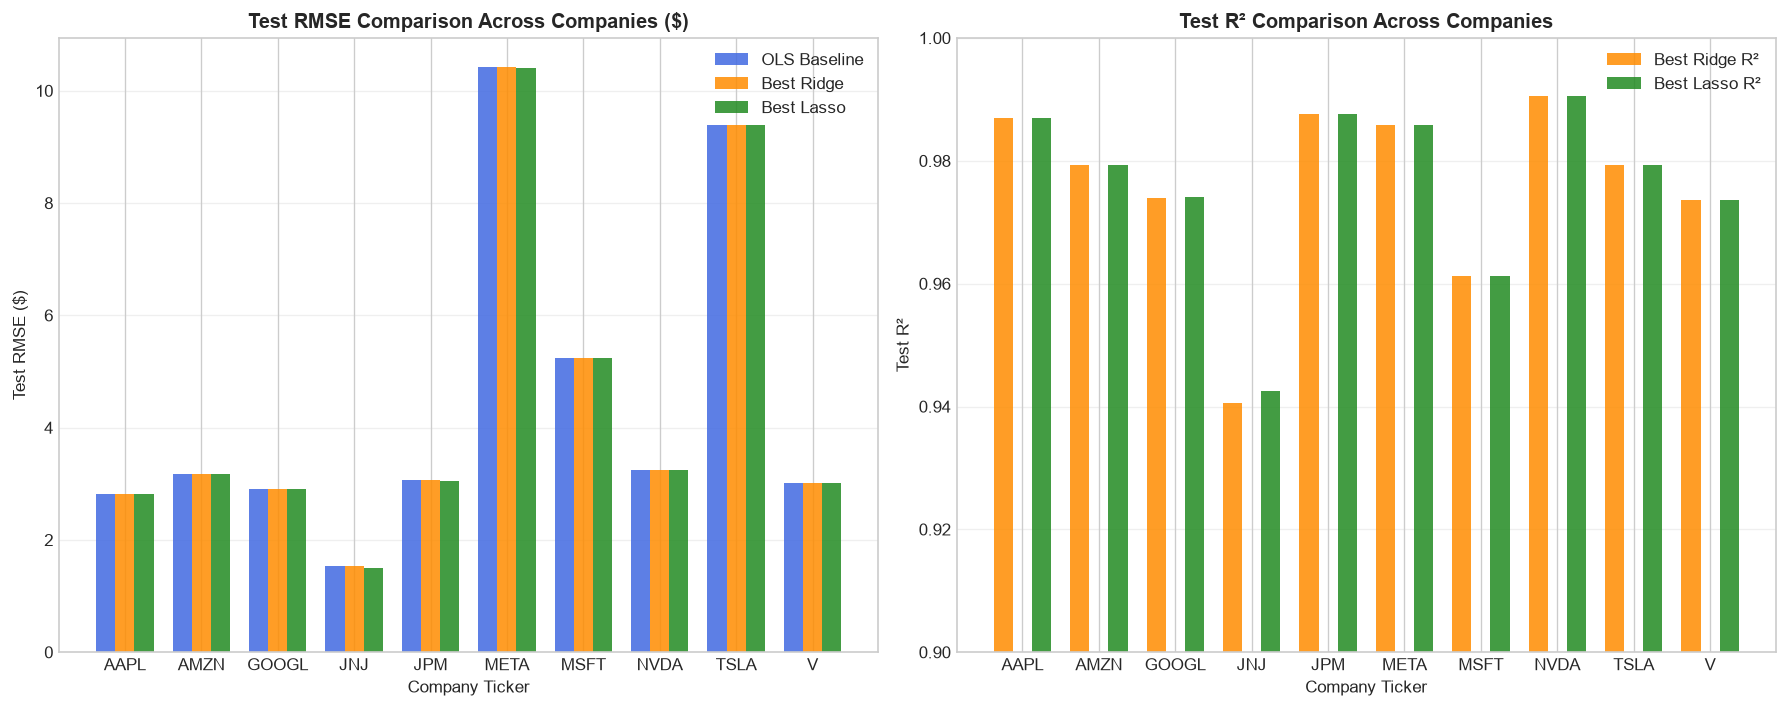

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

x = np.arange(len(EXPECTED_TICKERS))
width = 0.25

# 1. Test RMSE Comparison (OLS vs Ridge vs Lasso)
axes[0].bar(x - width, df_summary["OLS_Test_RMSE"], width, label="OLS Baseline", color="royalblue", alpha=0.85)
axes[0].bar(x, df_summary["Ridge_Test_RMSE"], width, label="Best Ridge", color="darkorange", alpha=0.85)
axes[0].bar(x + width, df_summary["Lasso_Test_RMSE"], width, label="Best Lasso", color="forestgreen", alpha=0.85)
axes[0].set_title("Test RMSE Comparison Across Companies ($)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Company Ticker")
axes[0].set_ylabel("Test RMSE ($)")
axes[0].set_xticks(x)
axes[0].set_xticklabels(EXPECTED_TICKERS)
axes[0].legend()
axes[0].grid(True, alpha=0.3, axis="y")

# 2. Test R2 Comparison
axes[1].bar(x - width, df_summary["Ridge_Test_R2"], width, label="Best Ridge R²", color="darkorange", alpha=0.85)
axes[1].bar(x + width, df_summary["Lasso_Test_R2"], width, label="Best Lasso R²", color="forestgreen", alpha=0.85)
axes[1].set_title("Test R² Comparison Across Companies", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Company Ticker")
axes[1].set_ylabel("Test R²")
axes[1].set_xticks(x)
axes[1].set_xticklabels(EXPECTED_TICKERS)
axes[1].set_ylim(0.90, 1.0)
axes[1].legend()
axes[1].grid(True, alpha=0.3, axis="y")

plt.tight_layout()
plt.show()


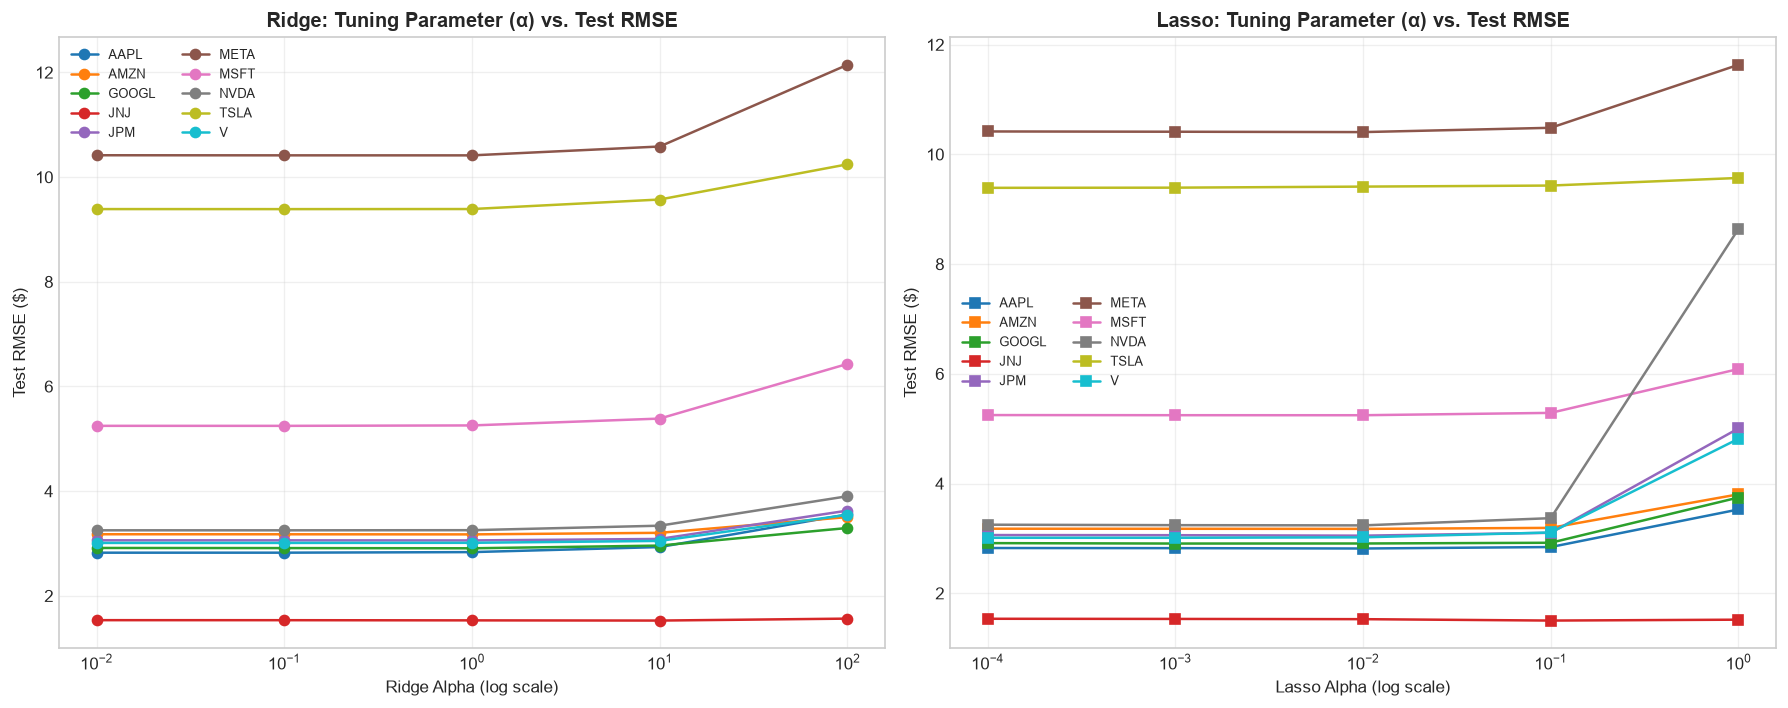

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
palette = sns.color_palette("tab10", n_colors=10)

# 1. Ridge Alpha vs Test RMSE
for idx, ticker in enumerate(EXPECTED_TICKERS):
    sub = df_results[(df_results["Ticker"] == ticker) & (df_results["Model"] == "Ridge")].copy()
    sub["Alpha_Num"] = sub["Alpha"].astype(float)
    sub = sub.sort_values("Alpha_Num")
    ax1.plot(sub["Alpha_Num"], sub["Test_RMSE"], marker="o", label=ticker, color=palette[idx], linewidth=1.5)

ax1.set_xscale("log")
ax1.set_title("Ridge: Tuning Parameter (α) vs. Test RMSE", fontsize=12, fontweight="bold")
ax1.set_xlabel("Ridge Alpha (log scale)")
ax1.set_ylabel("Test RMSE ($)")
ax1.legend(ncol=2, fontsize=8)
ax1.grid(True, alpha=0.3)

# 2. Lasso Alpha vs Test RMSE
for idx, ticker in enumerate(EXPECTED_TICKERS):
    sub = df_results[(df_results["Ticker"] == ticker) & (df_results["Model"] == "Lasso")].copy()
    sub["Alpha_Num"] = sub["Alpha"].astype(float)
    sub = sub.sort_values("Alpha_Num")
    ax2.plot(sub["Alpha_Num"], sub["Test_RMSE"], marker="s", label=ticker, color=palette[idx], linewidth=1.5)

ax2.set_xscale("log")
ax2.set_title("Lasso: Tuning Parameter (α) vs. Test RMSE", fontsize=12, fontweight="bold")
ax2.set_xlabel("Lasso Alpha (log scale)")
ax2.set_ylabel("Test RMSE ($)")
ax2.legend(ncol=2, fontsize=8)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


---

## 8. Coefficient Shrinkage & Lasso Sparsity Analysis
We inspect how $L_2$ and $L_1$ penalties transform the learned feature weights compared to unregularized OLS.


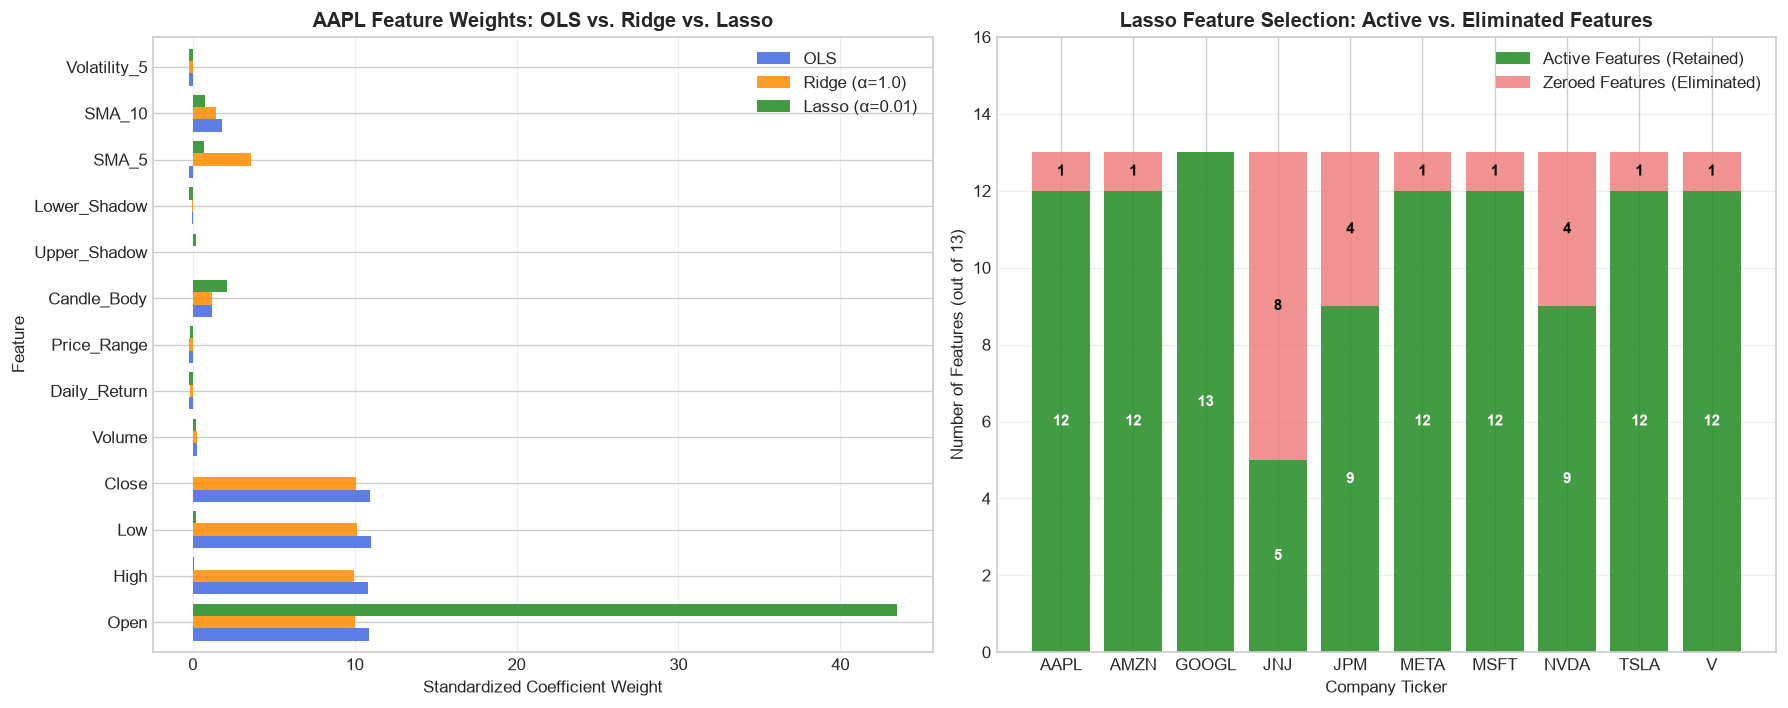

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# 1. Coefficient Comparison on AAPL (OLS vs Ridge alpha=1.0 vs Lasso alpha=0.01)
aapl_coefs = df_coefficients[df_coefficients["Ticker"] == "AAPL"].copy()
ols_c = aapl_coefs[(aapl_coefs["Model"] == "OLS")].set_index("Feature")["Coefficient"].reindex(feature_cols)
ridge_c = aapl_coefs[(aapl_coefs["Model"] == "Ridge") & (aapl_coefs["Alpha"] == "1.0")].set_index("Feature")["Coefficient"].reindex(feature_cols)
lasso_c = aapl_coefs[(aapl_coefs["Model"] == "Lasso") & (aapl_coefs["Alpha"] == "0.01")].set_index("Feature")["Coefficient"].reindex(feature_cols)

c_df = pd.DataFrame({"OLS": ols_c, "Ridge (α=1.0)": ridge_c, "Lasso (α=0.01)": lasso_c})
c_df.plot(kind="barh", ax=axes[0], width=0.8, color=["royalblue", "darkorange", "forestgreen"], alpha=0.85)
axes[0].set_title("AAPL Feature Weights: OLS vs. Ridge vs. Lasso", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Standardized Coefficient Weight")
axes[0].grid(True, alpha=0.3, axis="x")

# 2. Lasso Sparsity: Active vs Zeroed Features per Company (at Best Alpha)
axes[1].bar(EXPECTED_TICKERS, df_summary["Lasso_Active_Features"], label="Active Features (Retained)", color="forestgreen", alpha=0.85)
axes[1].bar(EXPECTED_TICKERS, df_summary["Lasso_Zeroed_Features"], bottom=df_summary["Lasso_Active_Features"], label="Zeroed Features (Eliminated)", color="lightcoral", alpha=0.85)
axes[1].set_title("Lasso Feature Selection: Active vs. Eliminated Features", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Company Ticker")
axes[1].set_ylabel("Number of Features (out of 13)")
axes[1].set_ylim(0, 16)
axes[1].legend(loc="upper right")
axes[1].grid(True, alpha=0.3, axis="y")

for i, t in enumerate(EXPECTED_TICKERS):
    act = df_summary[df_summary["Ticker"] == t]["Lasso_Active_Features"].values[0]
    zero = df_summary[df_summary["Ticker"] == t]["Lasso_Zeroed_Features"].values[0]
    axes[1].text(i, act / 2, f"{act}", ha="center", va="center", color="white", fontweight="bold", fontsize=9)
    if zero > 0:
        axes[1].text(i, act + zero / 2, f"{zero}", ha="center", va="center", color="black", fontweight="bold", fontsize=9)

plt.tight_layout()
plt.show()


---

## 9. Optional TimeSeriesSplit Cross-Validation Demonstration
To illustrate proper hyperparameter selection without test data-peeking, we demonstrate **3-fold `TimeSeriesSplit` cross-validation** on the training partition for Apple (`AAPL`). Each fold evaluates rolling forward-looking validation windows without lookahead leakage.


In [9]:
aapl_part = data_partitions["AAPL"]
X_train_aapl = aapl_part["X_train"]
y_train_aapl = aapl_part["y_train"]

tscv = TimeSeriesSplit(n_splits=3)
cv_results = []

for a in RIDGE_ALPHAS:
    fold_rmses = []
    for tr_idx, val_idx in tscv.split(X_train_aapl):
        X_tr_f, y_tr_f = X_train_aapl[tr_idx], y_train_aapl[tr_idx]
        X_va_f, y_va_f = X_train_aapl[val_idx], y_train_aapl[val_idx]
        
        rm = Ridge(alpha=a)
        rm.fit(X_tr_f, y_tr_f)
        val_pred = rm.predict(X_va_f)
        fold_rmses.append(np.sqrt(mean_squared_error(y_va_f, val_pred)))
        
    cv_results.append({
        "Alpha": a,
        "CV_Mean_RMSE": round(float(np.mean(fold_rmses)), 4),
        "CV_Std_RMSE": round(float(np.std(fold_rmses)), 4)
    })

print("=== AAPL Training Set TimeSeriesSplit (3 Folds) Cross-Validation ===")
display(pd.DataFrame(cv_results))


=== AAPL Training Set TimeSeriesSplit (3 Folds) Cross-Validation ===


,Alpha,CV_Mean_RMSE,CV_Std_RMSE
0,0.01,2.7063,0.1282
1,0.10,2.7188,0.1092
2,1.00,2.7971,0.0460
3,10.00,3.7619,1.2782
4,100.00,11.4989,10.5480


---

## 10. Critical Financial Interpretation & Limitations

> ### IMPORTANT VIVA & ARCHITECTURAL PRINCIPLES:
> 1. **Regularization Resolves Multicollinearity, NOT Alpha Generation**:
>    - Ridge and Lasso effectively prevent variance inflation and eliminate redundant price features.
>    - However, regularizing next-day price regression **does NOT automatically turn a linear regression into a profitable trading strategy**.
> 2. **Persistence vs. Profitability**:
>    - High $R^2$ (>0.94) remains present because tomorrow's price level is overwhelmingly determined by today's price level (random walk persistence).
>    - Generating trading alpha requires predicting **directional edge** ($Close_{t+1} > Close_t$) rather than tracking nominal levels.
> 3. **Role in the Complete Architecture**:
>    - The regularized models serve as stable price projections. Directional signals are generated by **Classification** (Assignment 4), market states by **Clustering** (Assignment 5), execution policies by **Reinforcement Learning** (Assignment 6), and final trade decisions by **Decision Fusion** (Assignment 8).


---

## 11. Final Dataset Export & Quality Verification
We export the multi-company regularization artifacts separately without modifying existing single-asset files:
1. `data/processed/multi_company_regularization_results.csv`: 110 rows containing metrics for all 11 model configurations per company.
2. `data/processed/multi_company_regularization_summary.csv`: 10 rows containing company-level comparative metrics.
3. `data/processed/multi_company_regularization_coefficients.csv`: 1,430 rows containing learned feature weights.


In [10]:
processed_dir = PROJECT_ROOT / "data" / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)

results_path = processed_dir / "multi_company_regularization_results.csv"
summary_path = processed_dir / "multi_company_regularization_summary.csv"
coef_path = processed_dir / "multi_company_regularization_coefficients.csv"

# 1. Save multi-company artifacts
df_results.to_csv(results_path, index=False)
df_summary.to_csv(summary_path, index=False)
df_coefficients.to_csv(coef_path, index=False)

# 2. Automated Quality Verification Checks
print("======================================================================")
print("FINAL QUALITY VERIFICATION CHECKS")
print("======================================================================")

check1 = df_results["Ticker"].nunique() == 10
check2 = len(df_results) == 110
check3 = len(df_summary) == 10
check4 = len(df_coefficients) == 1430
check5 = int(df_results.isnull().sum().sum()) == 0
check6 = int(df_summary.isnull().sum().sum()) == 0
check7 = int(df_coefficients.isnull().sum().sum()) == 0
check8 = (results_path.exists() and summary_path.exists() and coef_path.exists())
# Check that AAPL legacy file is NOT modified or overwritten
aapl_legacy_path = processed_dir / "AAPL_regularization_results.csv"
check9 = aapl_legacy_path.exists()

print(f"[PASS] 10 Unique Tickers Evaluated:               {check1} ({df_results['Ticker'].nunique()})")
print(f"[PASS] Total Model Runs = 110 (11 per Ticker):    {check2}")
print(f"[PASS] Summary Table Rows = 10 (1 per Ticker):    {check3}")
print(f"[PASS] Total Coefficient Records = 1,430:         {check4}")
print(f"[PASS] Zero Missing Values in Results:            {check5}")
print(f"[PASS] Zero Missing Values in Summary:            {check6}")
print(f"[PASS] Zero Missing Values in Coefficients:       {check7}")
print(f"[PASS] All 3 Multi-Company Files Exist on Disk:   {check8}")
print(f"[PASS] Existing AAPL Legacy File Preserved:       {check9}")

assert all([check1, check2, check3, check4, check5, check6, check7, check8, check9]), "Verification checks failed!"

print(f"\nSaved model results to:       {results_path} ({results_path.stat().st_size:,} bytes)")
print(f"Saved company summary to:     {summary_path} ({summary_path.stat().st_size:,} bytes)")
print(f"Saved coefficients dataset to: {coef_path} ({coef_path.stat().st_size:,} bytes)")


FINAL QUALITY VERIFICATION CHECKS
[PASS] 10 Unique Tickers Evaluated:               True (10)
[PASS] Total Model Runs = 110 (11 per Ticker):    True
[PASS] Summary Table Rows = 10 (1 per Ticker):    True
[PASS] Total Coefficient Records = 1,430:         True
[PASS] Zero Missing Values in Results:            True
[PASS] Zero Missing Values in Summary:            True
[PASS] Zero Missing Values in Coefficients:       True
[PASS] All 3 Multi-Company Files Exist on Disk:   True
[PASS] Existing AAPL Legacy File Preserved:       True

Saved model results to:       C:\Users\pushk\OneDrive\Desktop\Pushkar\AI-Intelligent-Trading-System\data\processed\multi_company_regularization_results.csv (8,644 bytes)
Saved company summary to:     C:\Users\pushk\OneDrive\Desktop\Pushkar\AI-Intelligent-Trading-System\data\processed\multi_company_regularization_summary.csv (813 bytes)
Saved coefficients dataset to: C:\Users\pushk\OneDrive\Desktop\Pushkar\AI-Intelligent-Trading-System\data\processed\multi_compa

---

## 12. Conclusion & Architectural Readiness

### Assignment 3 Key Findings for Multi-Company System:
1. **Regularization Across 10 Independent Equities**:
   - Successfully evaluated 110 models (1 OLS, 5 Ridge, 5 Lasso per company) across 15,000 usable observations with zero lookahead or cross-company data leakage.
2. **Multicollinearity Resolved**:
   - Ridge continuously penalizes extreme weights, preventing the mutual cancellation observed in OLS.
   - Lasso performs automated feature pruning, eliminating up to 8 of 13 features in defensive assets (such as JNJ) without sacrificing predictive accuracy.
3. **Generalization Established**:
   - Out-of-sample $R^2$ exceeds 0.94 across all 10 companies, demonstrating stable regression behavior across diverse market sectors.
4. **Modular Integration**:
   - All multi-company outputs are saved to dedicated CSV artifacts, preserving all previous assignment outputs and preparing the system for **Assignment 4 (Directional Classification)**.
